# Density maps of the histological annotations

Density (cells/mm²) of astrocytic inclusions and cytomegalic neurons for each slice, computed from the positions annotated in QuPath and displayed over the scan of the slice.

Inputs: `positions_histo/` (positions exported from QuPath) and `scans/slice{n}.jpg`. Outputs: `cmaps_histo/heatmap_histo_tranche{n}.png`.

In [47]:
import numpy as np
import pandas as pd
import openpyxl
import re

## Conversion of the QuPath exports to csv (run once)

In [48]:
# Run only once
# The x,y positions (µm) of the cells exported from QuPath are saved in an Excel file, one sheet per slice and annotation type.
# Each sheet is saved as a csv file with two columns x and y, named tranche{slice}-{annotation}_{version}.csv
# (annotation = inclusions or cytomegalics)

# Version of the annotations used for each slice
versions = {n : 'v2' for n in range(10,18)}
versions[12] = 'v0'
versions[17] = 'v0'

for v in ['v1','v2'] :
    classeur = openpyxl.load_workbook(f'positions_histo/qupath_global_{v}.xlsx')
    for sheetname in classeur.sheetnames :
        sheet = classeur[sheetname]
        data_sheet = sheet.values
        table = pd.DataFrame(data_sheet)
        table.columns = table.iloc[0]
        table.drop(0, inplace=True)
        table = table[["Centroid X µm","Centroid Y µm"]]
        table.dropna(inplace=True, how='all')
        table.dropna(inplace=True, how='all', axis = 1)
        table.columns = ['x','y']
        slice_n = re.findall(r'\d+', sheetname)[0]
        if 'AI' in sheetname : 
            annotation = 'inclusions'
        else : 
            annotation = 'cytomegalics'
        print(sheetname, slice_n, annotation, list(table.x)[:2], list(table.y)[:2])

        table.to_csv(f'positions_histo/tranche{slice_n}-{annotation}_{v}.csv', index = False, sep = ';')

MEA slice10 All Enlarged Neuron 10 cytomegalics [2702, 4084.8] [4303, 2846]
MEA slice10 AI 10 inclusions [4059.3, 1924.5] [2627.5, 4203.6]
MEA slice11 enlarged neurons 11 cytomegalics [1491.7, 5058.4] [4386.9, 4268.8]
MEA slice11 AI 11 inclusions [1273.9, 3839.5] [4648.8, 5130.7]
MEA slice13 Enlarged Neuron 13 cytomegalics [1329.9, 2181.8] [1287.4, 2080.8]
MEA slice13 AI 13 inclusions [1764.4, 2201] [3982.4, 3796.1]
MEA slide14 Enlarged Neur 14 cytomegalics [20119, 20741.3] [4100.5, 2630.4]
MEA slice14 AI 14 inclusions [18657.1, 18646.8] [4968.9, 5933]
MEA slice15 All Enlarged Neuron 15 cytomegalics [5209.7, 3519.5] [5373.6, 4943.3]
MEA slice15 AI 15 inclusions [3084.6, 3189.5] [6653.7, 6708.9]
MEA slice16 enlarged neurons 16 cytomegalics [22044.7, 20207.9] [4852.2, 5420.4]
MEA slice16 AI 16 inclusions [19378.7, 19653.7] [5471.8, 5176.6]
MEA slice10 All Enlarged Neuron 10 cytomegalics [3997.3, 2961.9] [5568.5, 4782.7]
MEA slice10 AI 10 inclusions ['none'] ['none']
MEA slice11 enlarged 

## Loading of the positions and of the pictures

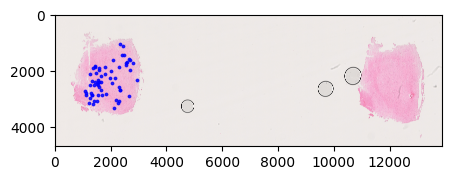

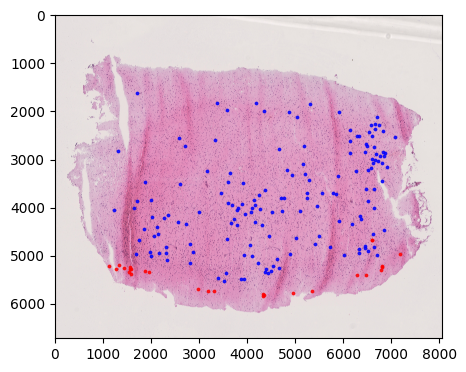

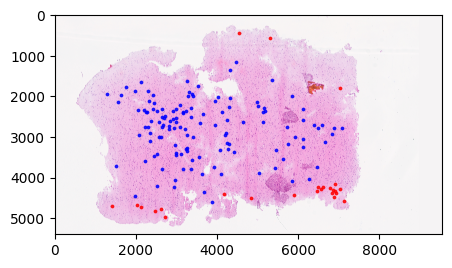

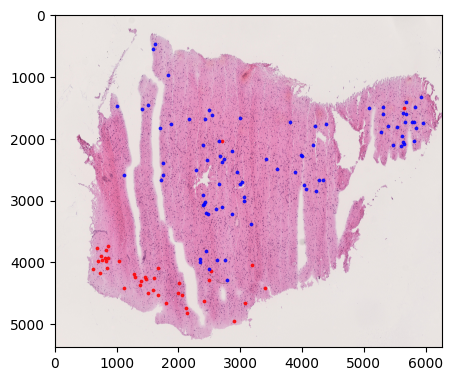

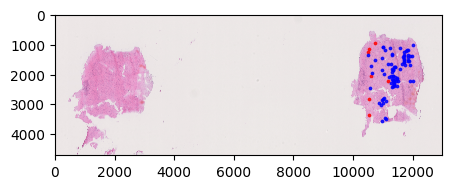

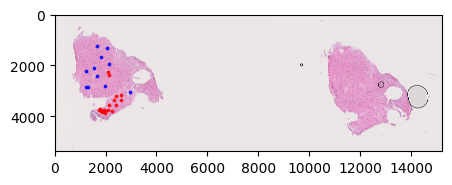

c:\Users\melina.scopin\Documents\local-env\.venv\Lib\site-packages\PIL\Image.py:3452: DecompressionBombWarning: Image size (98262528 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


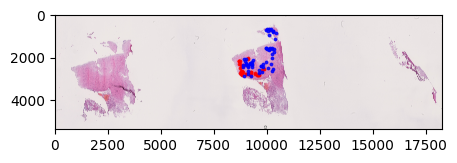

c:\Users\melina.scopin\Documents\local-env\.venv\Lib\site-packages\PIL\Image.py:3452: DecompressionBombWarning: Image size (97278720 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


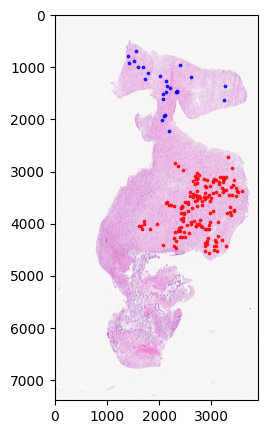

In [49]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
# The pictures are jpg images exported from QuPath, downscaled to be able to save them.
# The positions (µm) are converted to pixels of the downscaled picture: px = µm / (downscale factor * µm per pixel)

astros = {}
cytos = {}
images = {}
xlims = {}
ylims = {}

um= 0.2212  # µm per pixel of the full resolution scans
# Downscale factor of the exported picture, for each annotation version and slice
factors = {'v0' : {'12' : 4, '17' : 8},
           'v1' : {'10' : 6, '11' : 4, '12' : 4, '13' : 4, '14' : 8, '15' : 8, '16' : 10, '17' : 8},
           'v2' : {'10' : 8, '11' : 4, '12' : 4, '13' : 4, '14' : 8, '15' : 8, '16' : 10, '17' : 8}, 
           } 

# Crop of the picture (in pixels) for slices where only part of the picture is used
image_crop = {'17' : {'x' : [int(3700/(factors['v2']['17']*um)), 6000], 'y' : [0,7392]}}
images_folder = Path('./scans')

r = 3 # marker size 
a = 0.8 # alpha marker

for s in range (10,18) :

    v = versions[s]

    s = str(s) 

    image_path = images_folder / f'slice{s}.jpg'


    astro_file = Path('positions_histo') / f'tranche{s}-inclusions_{v}.csv'
    cytomegalics_file = Path('positions_histo') / f'tranche{s}-cytomegalics_{v}.csv'

    astro = pd.read_csv(astro_file, sep = ';')
    cyto = pd.read_csv(cytomegalics_file, sep = ';')
    image= np.asarray(Image.open(image_path))
    factor = factors[v][s]

    f,ax = plt.subplots(figsize = (5,5))

    if s in list(image_crop.keys()) :
        image_cropped = image[image_crop[s]['y'][0]:image_crop[s]['y'][1],image_crop[s]['x'][0]:image_crop[s]['x'][1],:]
    else :
        image_cropped = image

    ax.imshow(image_cropped)

    if len(astro.x) > 0 and astro.x[0] != 'none':
        astro = {'x' : astro.x/(factor*um), 'y' : astro.y/(factor*um)}
    else : 
        astro = {'x' : [], 'y' : []}

    if len(cyto.x) > 0 and cyto.x[0] != 'none':
        cyto = {'x' : cyto.x/(factor*um), 'y' : cyto.y/(factor*um)}
    else :
        cyto = {'x' : [], 'y' : []}

    # Check: inclusions in red, cytomegalic neurons in blue
    ax.scatter(astro['x'], astro['y'], color = 'red', s = r, alpha = a)
    ax.scatter(cyto['x'], cyto['y'], color = 'blue',  s = r, alpha = a)

    astros[s] = astro
    cytos[s] = cyto
    images[s] = image
    xlims[s] = ax.get_xlim()
    ylims[s] = ax.get_ylim()

    plt.show()

# Region of interest (in pixels) for some slices
xlims['10'] = (0,5000)
ylims['10'] = (6000,0)
xlims['14'] = (9500,12500)
ylims['14'] = (4500,500)
xlims['15'] = (200,5000)
ylims['15'] = (5000,100)
xlims['16'] = (8000,12000)

## Density maps

In [50]:
# Colormap whose transparency increases with the value (quadratic, low values transparent)
from matplotlib.colors import ListedColormap
def add_linear_transparency(cmap) :
    my_cmap = cmap(np.arange(cmap.N))
    my_cmap[:, -1] = np.ones(cmap.N) - np.square(np.linspace(1, 0, cmap.N))
    my_cmap = ListedColormap(my_cmap)
    return my_cmap


C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


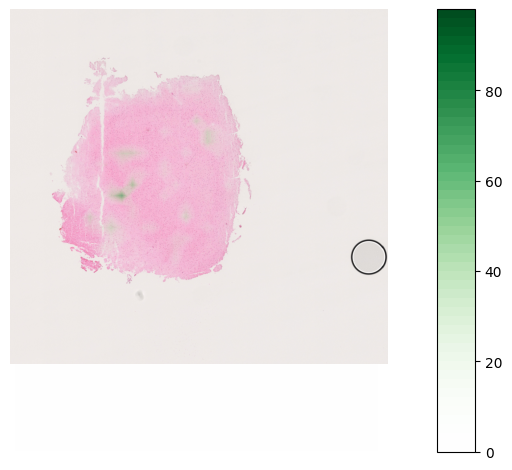

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


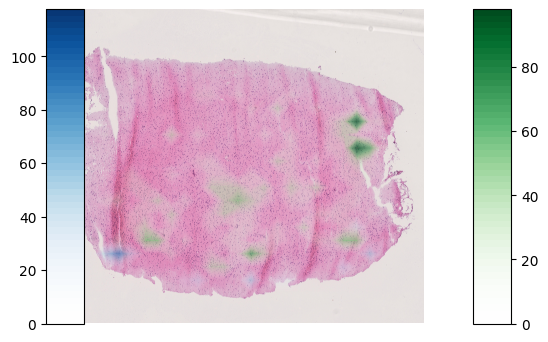

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


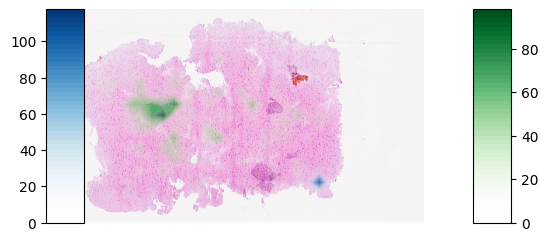

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


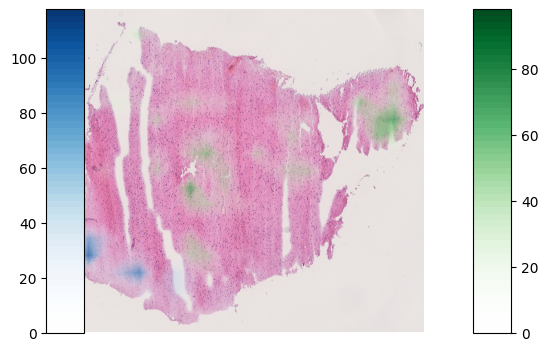

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


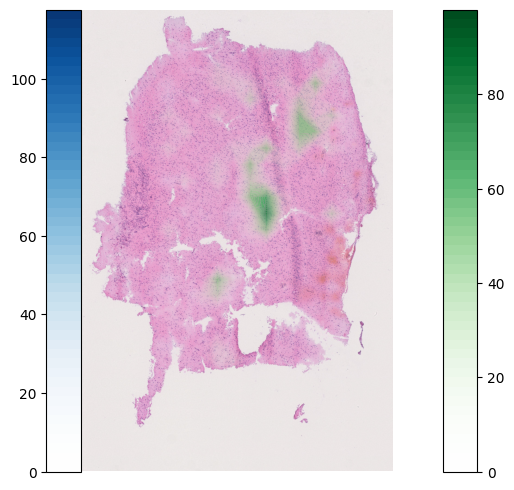

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


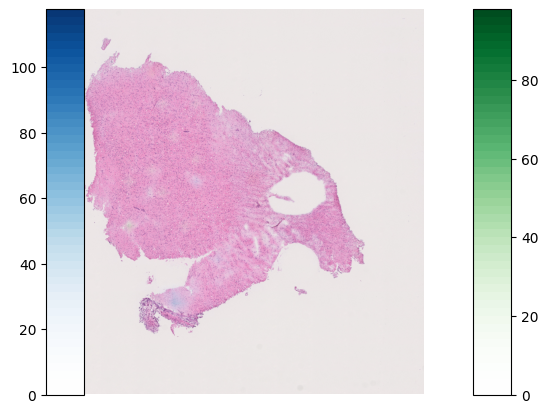

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


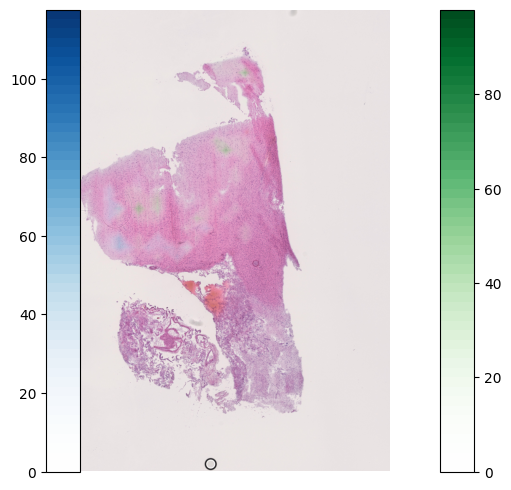

C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)
C:\Users\melina.scopin\AppData\Local\Temp\ipykernel_27472\2677899089.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = clm.get_cmap(cmap)


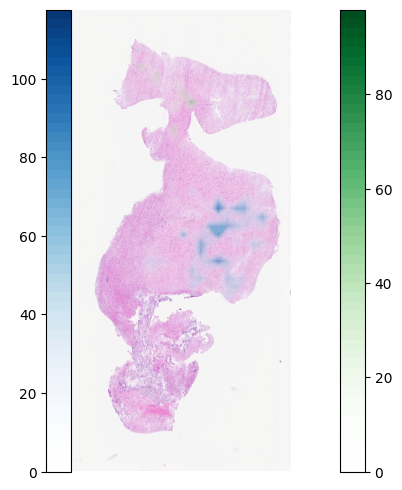

In [51]:
%matplotlib inline

from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib


steps_color = 50  # number of levels of the contour plots
ums = {'10' : 0.2212, '11' : 0.2212, '12' : 0.2212, '13' : 0.2212, '14' : 0.2212, '15' : 0.2212, '16' : 0.2212, '17' : 0.2212}

# Annotation types, colormaps, colormap limits and ticks (cells/mm²)
labels = ['Astrocytic inclusions', 'Cytomegalic neurons']
colors = {'Astrocytic inclusions': 'Blues', 'Cytomegalic neurons': 'Greens'}
lim_colors =  {'Astrocytic inclusions': [0,120], 'Cytomegalic neurons': [0,100]}
color_ticks = {'Astrocytic inclusions': [0,20,40,60,80,100,120], 'Cytomegalic neurons': [0,20,40,60,80,100]}
sides = ['left', 'right']  # side of the colorbar for each annotation type
bin_size_mm = 0.250 # size of the density bins (mm)

for a, s in enumerate(range (10,18)) :

    v = versions[s]

    s = str(s)

    image = images[s]
    factor = factors[v][s]
    um = ums[s]
    astro = astros[s].copy()
    cyto = cytos[s].copy()
    xlim = xlims[s]
    ylim = ylims[s]
    

    if s in list(image_crop.keys()) :
        image_cropped = image[image_crop[s]['y'][0]:image_crop[s]['y'][1],image_crop[s]['x'][0]:image_crop[s]['x'][1],:]
    else :
        image_cropped = image

    # Region of interest
    image_cropped = image_cropped[int(ylim[1]):int(ylim[0]), int(xlim[0]):int(xlim[1]), :]

    # Size and number of the bins in pixels
    bin_size_px = 1000*bin_size_mm/(factor*um)
    binsx = int((xlim[1]-xlim[0])/bin_size_px)
    binsy = int((ylim[0]-ylim[1])/bin_size_px)

    fig, ax = plt.subplots(figsize = (6,6))
    ax.imshow(image_cropped)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)


    for p, positions in enumerate([astro, cyto]) : 

        if len(positions['x']) > 0 : 

            label = labels[p]
            cmap = colors[label]
            cmap = matplotlib.colormaps[cmap]  # returns a copy of the colormap

            positions = pd.DataFrame(positions)

            # Positions relative to the region of interest
            if s in xlims.keys() :
                positions.x = positions.x - xlim[0]
            
            if s in ylims.keys() :
                positions.y = positions.y - ylim[1]

            # Density of cells (cells/mm²) in each bin; X, Y are the bin centers
            X = [0 for _ in range (binsx)] 
            Y = [0 for _ in range (binsy)] 
            Z = [[0 for _ in range (binsx)] for _ in range (binsy)]

            for i in range (binsy) :
                ymin = bin_size_px*i
                ymax = bin_size_px*i + bin_size_px
                Y[i] = ymin + (ymax-ymin)/2
                for ii in range (binsx) : 
                    xmin = bin_size_px*ii 
                    xmax = bin_size_px*ii + bin_size_px
                    X[ii] = xmin + (xmax-xmin)/2

                    if len(list(positions.index[(positions.x >= xmin)&(positions.x < xmax)&(positions.y >= ymin)&(positions.y < ymax)])) > 0 : 
                        # ax.scatter(X[ii], Y[i])
                        Z[i][ii] = len(list(positions.index[(positions.x >= xmin)&(positions.x < xmax)&(positions.y >= ymin)&(positions.y < ymax)]))/(bin_size_mm**2)
                            

            if lim_colors is not None : 
                minZ = lim_colors[label][0]
                maxZ = lim_colors[label][1]
            else : 
                maxZ = max([max(zi) for zi in Z])
                maxZ = maxZ + maxZ/10
                minZ = min([min(zi) for zi in Z]) 
                
            # Values below the lower limit are white, transparency increases with the density
            mapcolors = cmap
            mapcolors.set_under(color='white', alpha = 1)
            mapcolors = add_linear_transparency(mapcolors)
            
            
            step = (maxZ-minZ)/steps_color
            levels = np.array([minZ+step*i for i in range (steps_color)])

            # Density map and its colorbar
            cbs = ax.contourf(X, Y, Z, cmap= mapcolors, levels = levels, antialiased=True, vmin = minZ, vmax =maxZ,  algorithm = 'serial')
                        
            divider = make_axes_locatable(ax)
            col_ax = divider.append_axes(sides[p], size="10%", pad=0.5)

            cbars = plt.colorbar(cbs, cax=col_ax, ticks =color_ticks[label])
            cbars.ax.set_yticklabels(color_ticks[label])
            if p == 0 : 
                cbars.ax.yaxis.tick_left()


    # Save the figure
    plt.savefig(f'cmaps_histo/heatmap_histo_tranche{s}.png', dpi = 300, bbox_inches = 'tight')
    plt.show()
